# Tiled inference

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Scaling inference across tiles and comparing results visually
</div>
<!-- markdownlint-enable MD033 -->

---

Everything so far has processed one 128-by-128 patch. This page scales the same workflow to larger regions, and adds a qualitative comparison against genuine high-resolution basemap imagery, with an important caveat about what that comparison can and cannot prove.

---

## 1. Motivation

Real projects rarely need just one small patch enhanced. Knowing how tiling works here, and knowing how to sanity-check output against real high-resolution imagery without over-trusting that check, is what makes this workflow usable beyond a single demonstration patch.

---

## 2. Core idea

For any region larger than LDSR-S2's native 128-by-128 input size, `geoai.super_resolution()` automatically tiles the input into overlapping patches, runs the encode-denoise-decode pipeline on each independently, and stitches the results back together using linear blending across the overlap regions, the same {term}`tiled inference <Tiled Inference>` idea you have now seen across detection, segmentation, and here, image translation.

---

## 3. Workflow

### A. Run tiled super-resolution

Start by loading the same Granada scene as on the previous pages. If the file was already downloaded there, it is reused rather than downloaded again.

In [8]:
import geoai
from matplotlib import pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L09/data/S2A_L2A_20260802_N0512_R094_subset_Granada.tif"
s2_path = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

Then run super-resolution on a 256-by-256 region, four times the area of the single patch from before:

In [9]:
sr_large = str(OUT_DIR / "sr_large.tif")
sr_large_img, _ = geoai.super_resolution(
    input_lr_path=s2_path,
    output_sr_path=sr_large,
    rgb_nir_bands=[1, 2, 3, 4],
    window=(700, 1300, 256, 256),
    patch_size=128,
    overlap=16,
    sampling_steps=100,
)

print(f"Input shape: (4, 256, 256) at 10 m")
print(f"Output shape: {sr_large_img.shape} at 2.5 m")

LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.
Loaded pretrained weights from:  /Users/wulf/.cache/torch/hub/checkpoints/opensr-ldsrs2_v1_0_0.ckpt
Input shape: (4, 256, 256) at 10 m
Output shape: (4, 1024, 1024) at 2.5 m


`patch_size=128` matches the model's native input size from two pages ago; `overlap=16` controls how many pixels adjacent patches share. Larger overlap values produce smoother transitions between patches at the seams, at the cost of more total patches to process and more computation time, the familiar quality-versus-cost trade-off from earlier pages.

### B. Compare the larger region

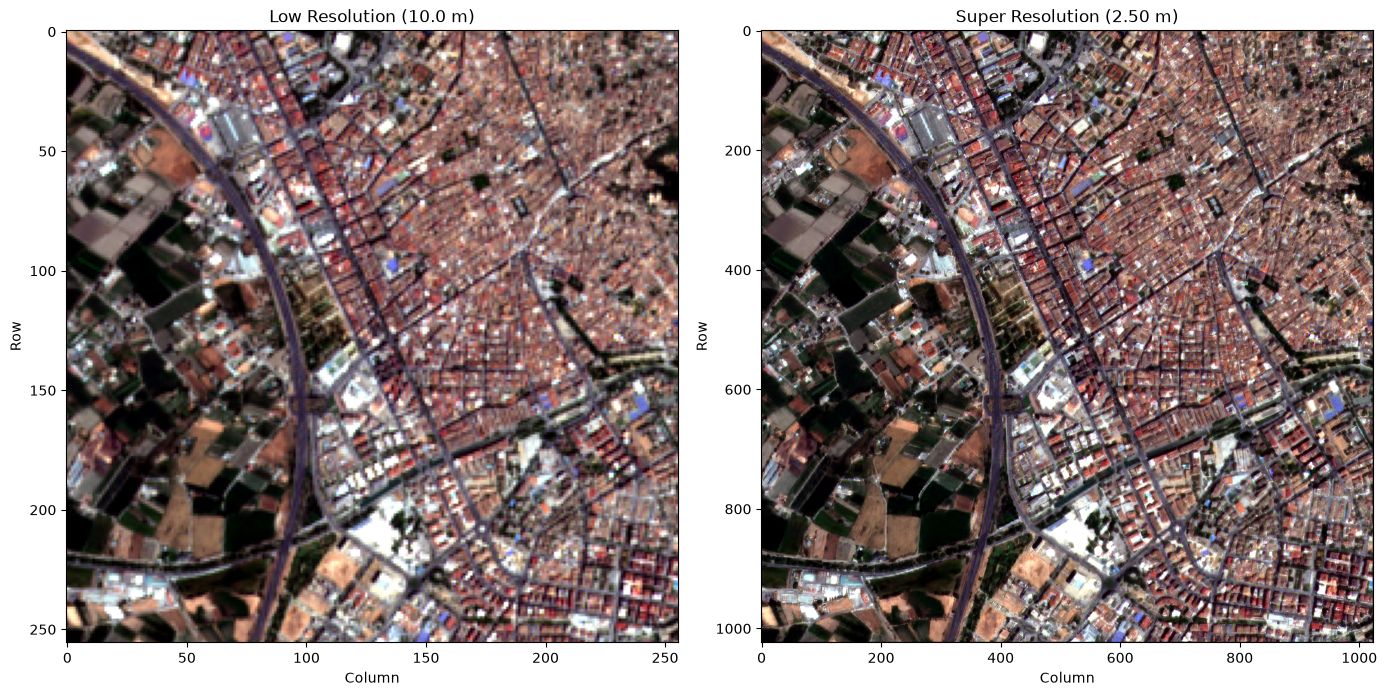

In [10]:
geoai.plot_sr_comparison(s2_path, sr_large, bands=[1, 2, 3])
plt.show()

This is the same comparison function from the single-patch workflow, now applied to the full stitched output, letting you visually confirm the tiling did not introduce obvious seams or discontinuities at patch boundaries.

### C. Compare against a basemap

In [11]:
geoai.create_split_map(
    left_layer=sr_large, right_layer="Esri.WorldImagery", left_args={"vmax": 0.3}
)

Map(center=[20, 0], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_text…

`create_split_map()` produces an interactive {term}`split-panel map <Split-Panel Map>`: dragging the slider reveals how well the super-resolved output's fine-scale detail matches what a genuinely high-resolution basemap shows in the same location.

### D. This comparison is qualitative only

```{admonition} The basemap is not ground truth for this comparison
:class: warning
Esri's World Imagery basemap may have been acquired on a different date, and processed through a different pipeline, than your Sentinel-2 scene. A mismatch between the two, a building that appears in one but not the other, a field boundary that looks different, can reflect real change over time or processing differences, not necessarily a model error. Use this comparison to build visual intuition, not as a rigorous accuracy assessment.
```

---

## 4. Python reactivation

Nothing new syntactically here; this page reuses the same function-call and dictionary patterns from earlier pages, applied to a larger `window` and a couple of new parameters (`patch_size`, `overlap`).

---

## 5. Common pitfalls

- **Setting `overlap=0` and expecting seamless output.** With no shared pixels between adjacent patches, boundary artifacts become more likely; some overlap is needed for the blending step to work well.
- **Setting `overlap` unnecessarily high.** Beyond a certain point, additional overlap mainly adds processing time without a proportional quality improvement; treat it the same way as `sampling_steps`, worth testing rather than maximizing by default.
- **Treating a basemap mismatch as proof of a model error.** As emphasized above, check acquisition dates before concluding the super-resolution output is wrong.
- **Skipping the full-region comparison in step B.** Tiling artifacts are sometimes only visible when viewing the stitched output as a whole, not in any single patch.

---

## 6. Mini task

You compare your super-resolved output against the Esri basemap and notice a building present in the basemap but missing from your Sentinel-2-derived output. List two possible explanations, and how you would distinguish between them.

:::{dropdown} Sample solution
:class: note

One possibility is that the building was constructed after the Sentinel-2 scene's acquisition date but before the basemap's, a genuine temporal difference rather than a model error. Another possibility is that the building is small enough, or has low enough contrast in the original 10-meter input, that the super-resolution model failed to reconstruct it. To distinguish between these, you would check the acquisition dates of both sources, and, if a genuine discrepancy remains after accounting for timing, examine the uncertainty map from the previous page at that specific location, since a model that failed to reconstruct a real feature would likely show elevated uncertainty there.
:::

---

## 7. Key takeaways

- `geoai.super_resolution()` handles tiling and overlap blending automatically for regions larger than the model's native patch size.
- `patch_size` and `overlap` trade processing time against how smooth the stitched output looks at patch boundaries.
- A split-map comparison against a high-resolution basemap is a useful qualitative check, not a rigorous accuracy assessment.
- Basemap and Sentinel-2 acquisition dates can differ, and mismatches may reflect real change over time rather than model error.